# The Steane Code in 10 Questions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaldoAlberto/steane-code/blob/main/steane_demo.ipynb)

Today's best qubits make a mistake roughly once every thousand to ten thousand operations. A useful quantum program needs
millions or billions of operations without one. Better hardware alone won't close that gap: the computer has
to find and fix its own errors while it runs. That is **quantum error correction**.

This notebook answers the ten questions I hear most about it, using the **Steane code**, the smallest code
of its family (CSS codes, explained in Q6) that fixes any error on a single qubit.

**How to read it:** run the cells from top to bottom. Each question has a short answer, a cell that shows it,
and a line on what it means. When a new idea appears for the first time, a **New idea** box explains it
first. No previous knowledge of error correction is needed.

**You will learn to:**
- explain why a qubit can't be backed up, and how checks find errors without reading the data;
- build the Steane code, find and fix any single error in a dynamic circuit;
- measure how much the code helps, and where it stops helping;
- say why noisy checks and fast decoders are the hard part today.

**You need:** basic Python. No quantum background. **Time:** about 30–40 minutes to read; the cells run in
about 10 seconds on a laptop.

## Questions

1. [Why can't we just copy the qubit and compare?](#q1)
2. [Then how do we find an error without looking?](#q2)
3. [How do we put one qubit into seven?](#q3)
4. [How do we ask the checks without measuring the data?](#q4)
5. [Does it really fix any single error?](#q5)
6. [And if two errors happen?](#q6)
7. [How much does it help with random noise?](#q7)
8. [Is there a point where the code stops helping?](#q8)
9. [Can we compute on the encoded qubit?](#q9)
10. [So why don't we have error-free quantum computers yet?](#q10)

[Setup](#setup) · [Key takeaways](#takeaways) · [Additional information](#additional-information)

<a id="setup"></a>
## Setup

We use three Python tools:
- **Qiskit** to build quantum circuits and look inside small ones,
- **Qiskit Aer** to run circuits many times, as a real device would,
- **stim** to run very large numbers of noisy runs quickly (Q7).

In a fresh environment, uncomment the first line. Then run the setup cells once. The last line prints the
versions; this notebook was tested with the ones shown in its saved output.

A few cells are marked **Behind the scenes**. They hold the machinery and open collapsed in Jupyter
(Colab and GitHub show them open). Run them, and skip reading them if you like.

In [1]:
# !pip install -q qiskit qiskit-aer stim numpy matplotlib pylatexenc
import itertools

import matplotlib.pyplot as plt
import numpy as np
import stim
from IPython.display import SVG, display
from matplotlib.patches import Polygon
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Pauli, Statevector
from qiskit_aer import AerSimulator

sim = AerSimulator()

import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| stim", stim.__version__)

qiskit 2.2.3 | qiskit-aer 0.17.2 | stim 1.14.0


> **New idea: qubit, superposition and measurement**
>
> A **qubit** can be $|0\rangle$, $|1\rangle$, or a **superposition** of both, like
> $|+\rangle = (|0\rangle + |1\rangle)/\sqrt 2$. **Measuring** it gives 0 or 1 at random (50/50 for $|+\rangle$)
> and destroys the superposition: after the measurement it is just 0 or 1.
>
> Two gates appear everywhere in this notebook:
> - **H (Hadamard)** turns $|0\rangle$ into $|+\rangle$ and back.
> - **CNOT** flips a second qubit (the *target*) when the first one (the *control*) is 1.
>
> In a simulator we are allowed to peek at the full state without measuring. `Statevector` does that and
> lists the probability of each outcome, written as a string of bits (Qiskit writes qubit 0 on the **right**).

<a id="q1"></a>
## Q1. Why can't we just copy the qubit and compare?

**Short answer:** because quantum mechanics forbids it (the *no-cloning theorem*). A circuit that copies 0 and 1 perfectly fails on a superposition: instead of two copies, you get two linked qubits.

In [2]:
copy = QuantumCircuit(2)
copy.h(0)          # the qubit we want to copy: |+>
copy.cx(0, 1)      # a CNOT copies 0 -> 00 and 1 -> 11 ...

got = Statevector(copy).probabilities_dict()
want = Statevector.from_label("++").probabilities_dict()
print("two real copies of |+> would give:", {k: round(v, 2) for k, v in want.items()})
print("the 'copy' circuit gives:         ", {k: round(v, 2) for k, v in got.items()})

two real copies of |+> would give: {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}
the 'copy' circuit gives:          {'00': 0.5, '11': 0.5}


Two real copies would give all four outcomes. The circuit only gives `00` or `11`: the two qubits are now
**entangled**, always equal when measured, but neither one is a copy of the original.

**What this means:** we can't keep backups of a qubit. Whatever protection we build has to work on the original.

> **New idea: two kinds of quantum error**
>
> A classical bit can only flip. A qubit can go wrong in two basic ways:
> - a **bit flip** ($X$ error) swaps $|0\rangle$ and $|1\rangle$,
> - a **phase flip** ($Z$ error) leaves 0 and 1 alone but turns $|+\rangle$ into $|-\rangle$.
>
> A **$Y$ error** is both at once. Any small error on one qubit can be described as a mix of these.
> Measuring the checks makes that mix "choose": no error, $X$, $Y$ or $Z$. So fixing just these three is
> enough to fix any error, even a tiny rotation.
>
> The cell below shows each error where it matters: a bit flip changes a 0 into a 1, while a phase flip is
> invisible when we read 0/1 and only shows up when we read in the $|+\rangle/|-\rangle$ basis (an H gate
> before measuring). In the output, `{'0': 1.0}` means the answer was 0 every time.

In [3]:
def outcome(start_plus, error):
    "Prepare |0> or |+>, apply the error, and read it in the basis where that start is a sure answer."
    qc = QuantumCircuit(1)
    if start_plus:
        qc.h(0)
    if error:
        getattr(qc, error)(0)
    if start_plus:
        qc.h(0)                                   # read |+> as 0 and |-> as 1
    return {k: round(v, 2) for k, v in Statevector(qc).probabilities_dict().items() if v > 1e-9}


print("                start |0>, read 0/1     start |+>, read +/- (via H)")
for name, error in [("no error", None), ("bit flip X", "x"), ("phase flip Z", "z")]:
    print(f"{name:<14}  {str(outcome(False, error)):<22}  {outcome(True, error)}")

                start |0>, read 0/1     start |+>, read +/- (via H)
no error        {'0': 1.0}              {'0': 1.0}
bit flip X      {'1': 1.0}              {'0': 1.0}
phase flip Z    {'0': 1.0}              {'1': 1.0}


<a id="q2"></a>
## Q2. Then how do we find an error without looking?

**Short answer:** we ask yes/no questions about groups of qubits, never about one qubit. With the right groups, the answers spell out the position of the error. The idea comes from Richard Hamming's classical code from 1950.

> **New idea: parity check**
>
> The **parity** of a group of bits is whether it has an even or odd number of 1s. A **check** measures only
> that: it tells you "even" or "odd" without telling you any of the bits. If one bit in the group flips, the
> parity changes, so the check notices.

The Steane code uses 7 qubits, numbered 1 to 7, and three checks called **4**, **2** and **1**. Check $b$
looks at every qubit whose number contains $b$ in binary. For example $5 = 4 + 1$, so qubit 5 is in checks 4
and 1. When one qubit flips, add up the values of the checks that ring:

$$\text{position of the error} = 4\,s_4 + 2\,s_2 + 1\,s_1 \qquad (s_b = 1 \text{ if check } b \text{ rings})$$

check 4 looks at qubits [4, 5, 6, 7]
check 2 looks at qubits [2, 3, 6, 7]
check 1 looks at qubits [1, 3, 5, 7]


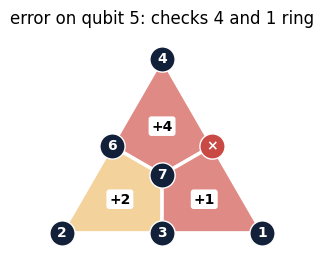

In [4]:
CHECK_VALUES = (4, 2, 1)
CHECKS = {b: [k for k in range(1, 8) if k & b] for b in CHECK_VALUES}
for b in CHECK_VALUES:
    print(f"check {b} looks at qubits {CHECKS[b]}")

POS = {4: (0.5, 0.866), 2: (0.0, 0.0), 1: (1.0, 0.0), 6: (0.25, 0.433), 5: (0.75, 0.433), 3: (0.5, 0.0),
       7: (0.5, 0.289)}
FACES = {4: [4, 6, 7, 5], 2: [2, 3, 7, 6], 1: [1, 5, 7, 3]}
FACE_COL = {4: "#9FD8D3", 2: "#F3D29B", 1: "#C9C3EA"}


def draw_code(error=None, title=""):
    "The 7 qubits (dots) and the 3 checks (tiles). Tiles that contain the error turn red."
    fig, ax = plt.subplots(figsize=(3.4, 3.0))
    for b, qs in FACES.items():
        on = error in qs
        ax.add_patch(Polygon([POS[q] for q in qs], closed=True, fc="#E08A86" if on else FACE_COL[b],
                             ec="white", lw=2.5))
        cx, cy = np.mean([POS[q] for q in qs], axis=0)
        ax.text(0.5 + (cx - 0.5) * 1.12, 0.289 + (cy - 0.289) * 1.12, f"+{b}", ha="center", va="center",
                fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"))
    for q, (x, y) in POS.items():
        ax.scatter(x, y, s=330, color="#C94A45" if q == error else "#13203A", zorder=3, edgecolor="white")
        ax.text(x, y, "×" if q == error else str(q), ha="center", va="center", color="white", zorder=4,
                fontweight="bold")
    ax.set_xlim(-0.15, 1.15); ax.set_ylim(-0.15, 1.0); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title)
    plt.show()


draw_code(error=5, title="error on qubit 5: checks 4 and 1 ring")

In [5]:
def syndrome(word):
    "Add up the values of the checks whose group has odd parity."
    return sum(b for b in CHECK_VALUES if sum(word[k - 1] for k in CHECKS[b]) % 2)


for k in range(1, 8):
    word = [0] * 7
    word[k - 1] = 1
    print(f"flip qubit {k}: checks add up to {syndrome(word)}")

flip qubit 1: checks add up to 1
flip qubit 2: checks add up to 2
flip qubit 3: checks add up to 3
flip qubit 4: checks add up to 4
flip qubit 5: checks add up to 5
flip qubit 6: checks add up to 6
flip qubit 7: checks add up to 7


The list of check answers is called the **syndrome**, like a doctor reading symptoms to find the cause.
For the quantum code we run the three checks **twice**: once looking for bit flips and once for phase flips.

**What this means:** three answers are enough to locate one error among seven qubits, and none of them reveals the data.

> **New idea: logical qubit**
>
> The qubits on the chip are **physical qubits**. The qubit we actually care about, spread over several
> physical ones, is the **logical qubit**. We write its states with an L: $|0_L\rangle$, $|1_L\rangle$.
> Turning one qubit's worth of information into the shared state of seven is called **encoding**.

<a id="q3"></a>
## Q3. How do we put one qubit into seven?

**Short answer:** with three Hadamards and a few CNOTs. The result is an equal mix of 8 bit patterns, and that mix is the encoded zero, $|0_L\rangle$.

Step by step:
1. Qubits 1, 2 and 4 each belong to a single check. An H puts each of them in superposition.
2. A CNOT from each of them to the other qubits of its check spreads that value over the whole group.

Because the groups overlap, the result is an equal mix of 8 bit patterns. Each one has an even number of
1s inside every check, so the bit-flip checks pass. The phase-flip checks pass too, because all 8 patterns are
mixed in equal amounts. That mix is $|0_L\rangle$.

<details><summary>Show the 8 patterns</summary>

$$|0_L\rangle = \tfrac{1}{\sqrt 8}\big(|0000000\rangle + |0001111\rangle + |0110011\rangle + |1010101\rangle
+ |0111100\rangle + |1011010\rangle + |1100110\rangle + |1101001\rangle\big)$$

(qubit 1 on the left)
</details>

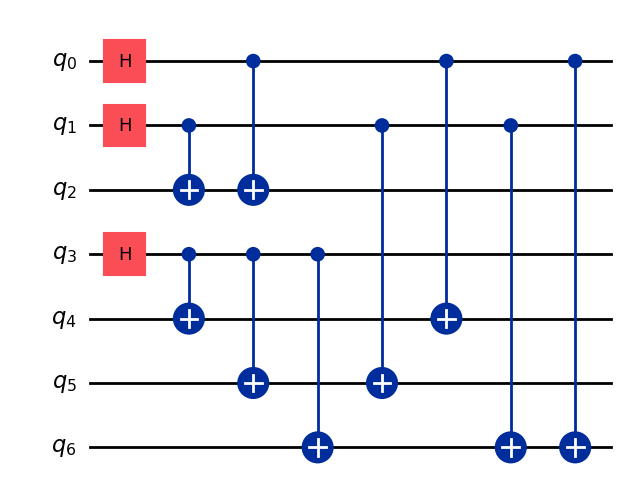

In [6]:
def encoder():
    qc = QuantumCircuit(7, name="encode")
    for b in CHECK_VALUES:
        qc.h(b - 1)                      # step 1
        for k in CHECKS[b]:
            if k != b:
                qc.cx(b - 1, k - 1)      # step 2
    return qc


encoder().draw("mpl")

> **New idea: stabilizer (a check written as an operator)**
>
> The three error types $X$, $Y$ and $Z$ are also called the **Pauli** operators. Each check can be written as
> Paulis on its 4 qubits. For example, the bit-flip check 4 is
> $Z_4 Z_5 Z_6 Z_7$ and the phase-flip check 4 is $X_4 X_5 X_6 X_7$. A healthy encoded state answers **+1** to all
> six; an error turns some answers into **−1**. These six operators are called the **stabilizers** of the code.
>
> The logical operators act on all 7 qubits at once: $X_L$ ($X$ on all 7 qubits) flips the logical qubit and
> $Z_L$ ($Z$ on all 7) reads its value ($+1$ for $|0_L\rangle$). You may see this written $X^{\otimes 7}$.

In [7]:
def stabilizers():
    "The 6 checks as Pauli operators (Qiskit writes qubit 0 as the last letter)."
    out = {}
    for P in "XZ":
        for b in CHECK_VALUES:
            out[f"{P}{b}"] = Pauli("".join(P if (7 - i) in CHECKS[b] else "I" for i in range(7)))
    return out


X_L, Z_L = Pauli("X" * 7), Pauli("Z" * 7)

psi = Statevector(encoder())
print("8 patterns, 1/8 each:", {k[::-1]: round(v, 3) for k, v in psi.probabilities_dict().items()})
print("the six checks answer:", {n: round(psi.expectation_value(P).real, 3) for n, P in stabilizers().items()})
print("Z_L =", round(psi.expectation_value(Z_L).real, 3), " -> this is the encoded 0")

8 patterns, 1/8 each: {'0000000': 0.125, '0111100': 0.125, '1011010': 0.125, '1100110': 0.125, '1101001': 0.125, '1010101': 0.125, '0110011': 0.125, '0001111': 0.125}
the six checks answer: {'X4': 1.0, 'X2': 1.0, 'X1': 1.0, 'Z4': 1.0, 'Z2': 1.0, 'Z1': 1.0}
Z_L = 1.0  -> this is the encoded 0


**What this means:** one logical qubit now lives in the pattern shared by seven physical qubits. No single qubit holds it.

> **New idea: helper qubit (ancilla)**
>
> To read a parity without measuring the data, we use an extra qubit that starts at 0, called a **helper** or
> **ancilla**. Each data qubit of the group sends a CNOT to the helper. Every 1 flips the helper once, so the
> helper ends up holding the parity. Then we measure only the helper.

In [8]:
for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    qc = QuantumCircuit(3, 1)                  # qubits 0, 1 = data, qubit 2 = helper
    if a: qc.x(0)
    if b: qc.x(1)
    qc.cx(0, 2); qc.cx(1, 2)                  # both data qubits talk to the helper
    qc.measure(2, 0)
    helper = sim.run(qc, shots=100).result().get_counts()
    print(f"data = {a}{b}  ->  helper reads {list(helper)[0]}  (parity {'odd' if (a + b) % 2 else 'even'})")

data = 00  ->  helper reads 0  (parity even)
data = 01  ->  helper reads 1  (parity odd)
data = 10  ->  helper reads 1  (parity odd)
data = 11  ->  helper reads 0  (parity even)


<a id="q4"></a>
## Q4. How do we ask the checks without measuring the data?

**Short answer:** with helper qubits, as above. We do it twice: once with CNOTs from the data to the helpers (these see bit flips), and once with H gates around CNOTs from the helpers to the data (these see phase flips).

The three answers are stored in a small register of classical bits, ordered so that the register, read as a
binary number, is the qubit to fix. The drawing shows the bit-flip half; the phase-flip half looks the same with H gates around the helpers.
The top 7 lines are the data and the 3 lines below are the
helpers.

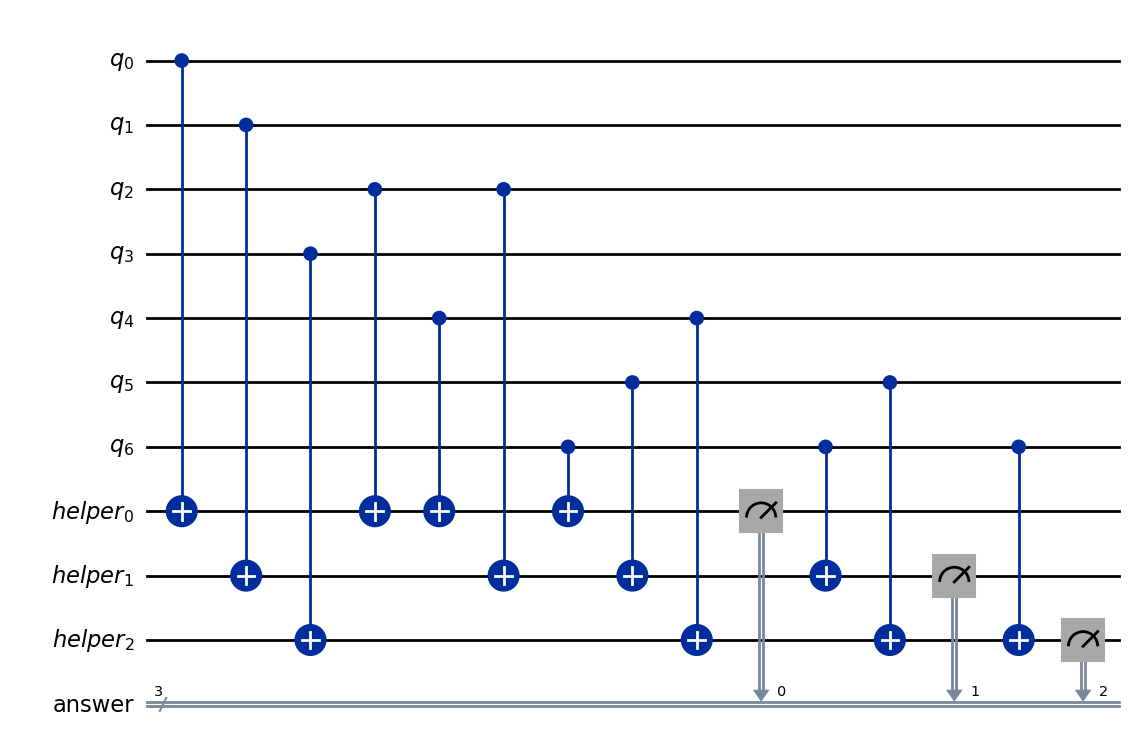

In [9]:
def measure_bit_flip_checks(qc, data, anc, c):
    for j, b in enumerate((1, 2, 4)):            # register bit j holds check 1, 2, 4
        for k in CHECKS[b]:
            qc.cx(data[k - 1], anc[j])
        qc.measure(anc[j], c[j])


def measure_phase_flip_checks(qc, data, anc, c):
    for j, b in enumerate((1, 2, 4)):
        qc.h(anc[j])
        for k in CHECKS[b]:
            qc.cx(anc[j], data[k - 1])
        qc.h(anc[j])
        qc.measure(anc[j], c[j])


data = QuantumRegister(7, "q"); helpers = QuantumRegister(3, "helper"); answer = ClassicalRegister(3, "answer")
picture = QuantumCircuit(data, helpers, answer)
measure_bit_flip_checks(picture, data, helpers, answer)
picture.draw("mpl", fold=-1)

**What this means:** this is the pattern behind every error-correcting quantum computer: measure the questions, never the answers.

> **New idea: dynamic circuit**
>
> In a basic circuit, all measurements happen at the end. A **dynamic circuit** measures some qubits in the
> middle and uses the result right away to decide what to do next. In Qiskit this is `with qc.if_test(...)`:
> "if the register reads $k$, apply this gate". That is exactly what a fix needs.
>
> To check the result, we **undo** the encoding at the end (run the encoder backwards). If the logical qubit is
> still healthy, all 7 qubits come back to 0.
>
> One catch: $|0_L\rangle$ doesn't change under a logical phase flip (just like $|0\rangle$ doesn't change
> under $Z$). So a test that starts from $|0_L\rangle$ can't see phase mistakes. We run every test twice:
> from $|0_L\rangle$, and from $|+_L\rangle$, where a phase flip shows up. To make $|+_L\rangle$ we apply H to
> all 7 qubits; that acts as an H on the logical qubit (Q9 checks it).
>
> Reading the result: `0000000` means the logical qubit survived. Any other pattern means it was damaged.

<a id="q5"></a>
## Q5. Does it really fix any single error?

**Short answer:** yes. We encode, add one error, measure the checks, fix during the circuit, and undo the encoding. All 21 cases ($X$, $Y$ or $Z$ on any of the 7 qubits) come back to 0000000, starting from both $|0_L\rangle$ and $|+_L\rangle$.

In [10]:
def correct(qc, data, sz, sx):
    for k in range(1, 8):
        with qc.if_test((sz, k)):      # bit-flip checks point to qubit k -> undo the bit flip
            qc.x(data[k - 1])
        with qc.if_test((sx, k)):      # phase-flip checks point to qubit k -> undo the phase flip
            qc.z(data[k - 1])

The next cell is collapsed: it glues the pieces together (encode, add errors, checks, fix, undo, read). Run it
and come back to the results below.

In [11]:
# Behind the scenes: the full error-correction cycle. Safe to run without reading.
def full_cycle(*errors, start="0"):
    "encode |0_L> or |+_L>, add errors such as ('x', 5), measure the checks, fix, undo, read the data"
    data = QuantumRegister(7, "q"); az = QuantumRegister(3, "az"); ax = QuantumRegister(3, "ax")
    sz = ClassicalRegister(3, "sz"); sx = ClassicalRegister(3, "sx"); out = ClassicalRegister(7, "out")
    qc = QuantumCircuit(data, az, ax, sz, sx, out)
    qc.compose(encoder(), data, inplace=True)
    if start == "+":
        qc.h(data)                                   # |0_L> -> |+_L>
    for gate, k in errors:
        getattr(qc, gate)(data[k - 1])
    measure_bit_flip_checks(qc, data, az, sz)
    measure_phase_flip_checks(qc, data, ax, sx)
    correct(qc, data, sz, sx)
    if start == "+":
        qc.h(data)                                   # |+_L> -> |0_L>
    qc.compose(encoder().inverse(), data, inplace=True)
    qc.measure(data, out)
    return qc


def data_after(*errors, start="0"):
    "Run the full cycle 200 times and return the data patterns we read at the end."
    counts = sim.run(full_cycle(*errors, start=start), shots=200, seed_simulator=1).result().get_counts()
    return {key.split()[0] for key in counts}


def fixed(*errors):
    "True only if the logical qubit survives starting from |0_L> AND from |+_L>."
    return all(data_after(*errors, start=s) == {"0000000"} for s in ("0", "+"))

In [12]:
# first, why two starting states: a logical phase flip (Z on all 7) is invisible from |0_L>
logical_z = [("z", k) for k in range(1, 8)]
print("logical phase flip, start |0_L> ->", data_after(*logical_z, start="0"), " (looks fine!)")
print("logical phase flip, start |+_L> ->", data_after(*logical_z, start="+"), " (caught)")
print()

all_ok = True
for gate in ("x", "y", "z"):
    row = []
    for k in range(1, 8):
        ok = fixed((gate, k))
        all_ok &= ok
        row.append(f"{k}:{'fixed' if ok else 'FAILED'}")
    print(f"{gate.upper()} error on qubit ->", "  ".join(row))
print("\nall 21 single-qubit errors fixed, in both tests:", all_ok)

logical phase flip, start |0_L> -> {'0000000'}  (looks fine!)
logical phase flip, start |+_L> -> {'0110100'}  (caught)

X error on qubit -> 1:fixed  2:fixed  3:fixed  4:fixed  5:fixed  6:fixed  7:fixed


Y error on qubit -> 1:fixed  2:fixed  3:fixed  4:fixed  5:fixed  6:fixed  7:fixed
Z error on qubit -> 1:fixed  2:fixed  3:fixed  4:fixed  5:fixed  6:fixed  7:fixed

all 21 single-qubit errors fixed, in both tests: True


**What this means:** a $Y$ error is a bit flip and a phase flip at once, so both sets of checks catch it. Any single error, of any kind, is covered.

> **New idea: logical error and code distance**
>
> A **logical error** is an error the code can't see or fixes the wrong way, so the logical qubit itself ends
> up changed. The **distance** of a code is the smallest number of physical errors that can change the logical
> qubit **without any check noticing**. For the Steane code that is 3 (for example $X$ on qubits 1, 2 and 3). A
> code of distance $d$ can always fix up to $(d-1)/2$ errors, so the Steane code fixes any **one** error. With
> two errors the checks do notice, but they point to the wrong qubit (the next cells show this).
>
> There is a bonus: the bit-flip checks and the phase-flip checks work independently (codes built this way are
> called **CSS codes**). So one bit flip **and** one phase flip, even on different qubits, are both fixed.

<a id="q6"></a>
## Q6. And if two errors happen?

**Short answer:** it depends on the kind. One bit flip plus one phase flip are caught by different checks, so both are fixed. Two bit flips fool the checks: they point to a third qubit, and the "fix" completes a logical error.

In [13]:
print("X on 3 + Z on 5 -> fixed in both tests:", fixed(("x", 3), ("z", 5)))
print("X on 2 + X on 5 -> data read:", data_after(("x", 2), ("x", 5)), "  <- not 0000000: a logical error")
print("checks point to qubit", syndrome([1 if k in (2, 5) else 0 for k in range(1, 8)]), "(2 + 5 errors look like 7)")

X on 3 + Z on 5 -> fixed in both tests: True
X on 2 + X on 5 -> data read: {'0110100'}   <- not 0000000: a logical error
checks point to qubit 7 (2 + 5 errors look like 7)


**What this means:** every code has a limit. Bigger codes, with larger distance, push it further, at the price of more qubits.

> **New idea: noise model**
>
> Real errors are random. The simplest model is **depolarizing noise**: each qubit, independently, gets an
> error with chance $p$, and that error is $X$, $Y$ or $Z$ with equal odds. A qubit with no code fails with
> chance $p$. The encoded qubit only fails when two or more errors confuse the checks, so for small $p$ we
> expect its failure rate to grow like $p^2$. Squaring a small number makes it much smaller.
>
> For now, only the 7 data qubits get noise; the checks themselves are **perfect**. Q10 removes that shortcut.

<a id="q7"></a>
## Q7. How much does it help with random noise?

**Short answer:** a lot, if the noise is low. At 1 % noise per qubit, the encoded qubit fails about 0.16 % of the time, and its failure rate falls like $p^2$.

> **New idea: stim, alarms and a reference qubit**
>
> Measuring a failure rate of 0.01 % needs hundreds of thousands of runs. **stim** is a simulator built for
> error-correction circuits that does this in seconds. The next cell is collapsed: it is the machinery, and you
> can run it without reading it. The experiment it builds:
>
> 1. Measure the six checks once, to start from a clean encoded state.
> 2. Add depolarizing noise to the 7 qubits.
> 3. Measure the checks again. A check whose answer changed is an **alarm**, and the alarms name the qubit to fix.
> 4. To see whether the fix worked, we use an 8th qubit linked (entangled) with the logical qubit at the start.
>    Comparing them at the end shows both kinds of logical failure in the same run.
>
> stim measures a whole check at once with `MPP` (measure a product of Paulis). We also compute the **exact**
> answer by going through all $4^7 = 16{,}384$ possible error patterns, to confirm the simulation.

In [14]:
# Behind the scenes: the stim experiment and the exact count. Safe to run without reading.
def pauli_product(P, qubits):
    return stim.target_combined_paulis([stim.target_x(q) if P == "X" else stim.target_z(q) for q in qubits])


def memory_circuit(p, check_error=0.0):
    checks, pair = [], []
    for P in ("X", "Z"):
        for b in (4, 2, 1):
            checks += pauli_product(P, [k - 1 for k in CHECKS[b]])
    pair += pauli_product("X", list(range(8)))       # logical qubit vs 8th qubit, X version
    pair += pauli_product("Z", list(range(8)))       # and Z version
    c = stim.Circuit()
    c.append("R", range(8))
    c.append("MPP", checks + pair)                     # 1. start
    c.append("DEPOLARIZE1", range(7), p)               # 2. noise
    c.append("MPP", checks, check_error)               # 3. checks again (perfect here)
    c.append("MPP", pair)                              # 4. compare with the 8th qubit
    for j in range(6):
        c.append("DETECTOR", [stim.target_rec(-8 + j), stim.target_rec(-16 + j)])          # alarms
    c.append("OBSERVABLE_INCLUDE", [stim.target_rec(-1), stim.target_rec(-9)], 0)    # logical bit flip?
    c.append("OBSERVABLE_INCLUDE", [stim.target_rec(-2), stim.target_rec(-10)], 1)   # logical phase flip?
    return c


def failure_rate(p, shots=400_000, seed=11, check_error=0.0):
    alarms, flips = memory_circuit(p, check_error).compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True)
    fix_bit = alarms[:, 3:6].any(axis=1)        # fixing any named qubit flips the logical qubit
    fix_phase = alarms[:, 0:3].any(axis=1)
    return float(((fix_bit != flips[:, 0]) | (fix_phase != flips[:, 1])).mean())


def exact_failure_rate(p):
    "Exact value: add the chance of every error pattern that fools the checks."
    def fails(v):
        s = sum(b for b in CHECK_VALUES if sum(v[k - 1] for k in CHECKS[b]) % 2)
        v = list(v)
        if s:
            v[s - 1] ^= 1
        return sum(v) % 2
    total = 0.0
    for err in itertools.product(range(4), repeat=7):     # 0 = none, 1 = X, 2 = Y, 3 = Z
        w = sum(1 for e in err if e)
        if fails([e in (1, 2) for e in err]) or fails([e in (2, 3) for e in err]):
            total += (1 - p) ** (7 - w) * (p / 3) ** w
    return total

The plot uses **logarithmic axes**: each step on an axis is ten times the previous one. On such a plot, a
rate that grows like $p$ is a line with slope 1 (the dashed line) and a rate that grows like $p^2$ is a line
twice as steep.

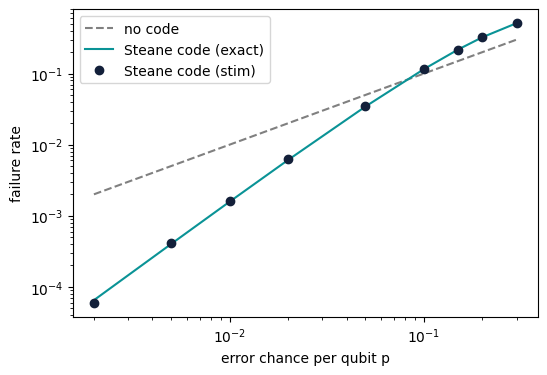

p = 0.002  stim 5.90e-05   exact 6.49e-05   failure / p² = 16.2
p = 0.005  stim 4.16e-04   exact 4.01e-04   failure / p² = 16.1
p = 0.01   stim 1.59e-03   exact 1.58e-03   failure / p² = 15.8
p = 0.02   stim 6.34e-03   exact 6.10e-03   failure / p² = 15.2
p = 0.05   stim 3.44e-02   exact 3.44e-02   failure / p² = 13.7
p = 0.1    stim 1.15e-01   exact 1.15e-01   failure / p² = 11.5
p = 0.15   stim 2.17e-01   exact 2.18e-01   failure / p² = 9.7
p = 0.2    stim 3.24e-01   exact 3.24e-01   failure / p² = 8.1
p = 0.3    stim 5.12e-01   exact 5.11e-01   failure / p² = 5.7


In [15]:
ps = np.array([0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3])
sim_rate = np.array([failure_rate(p, shots=2_000_000 if p < 0.01 else 400_000, seed=11 + i)
                     for i, p in enumerate(ps)])
exact_rate = np.array([exact_failure_rate(p) for p in ps])

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ps, ps, "--", color="gray", label="no code")
ax.loglog(ps, exact_rate, "-", color="#0A9396", label="Steane code (exact)")
ax.loglog(ps, sim_rate, "o", color="#13203A", label="Steane code (stim)")
ax.set_xlabel("error chance per qubit p"); ax.set_ylabel("failure rate"); ax.legend(); plt.show()

for p, s, e in zip(ps, sim_rate, exact_rate):
    print(f"p = {p:<6} stim {s:.2e}   exact {e:.2e}   failure / p² = {e / p**2:.1f}")

**What this means:** the simulation and the exact count agree, and at small $p$ the failure rate is about $16\,p^2$. That is the promise of error correction: below a certain noise level, protection beats the extra qubits it costs.

Curious what stim actually ran? Here is the circuit: time goes left to right, `MPP` boxes are check
measurements, and `DEPOLARIZE1` is where the noise hits.

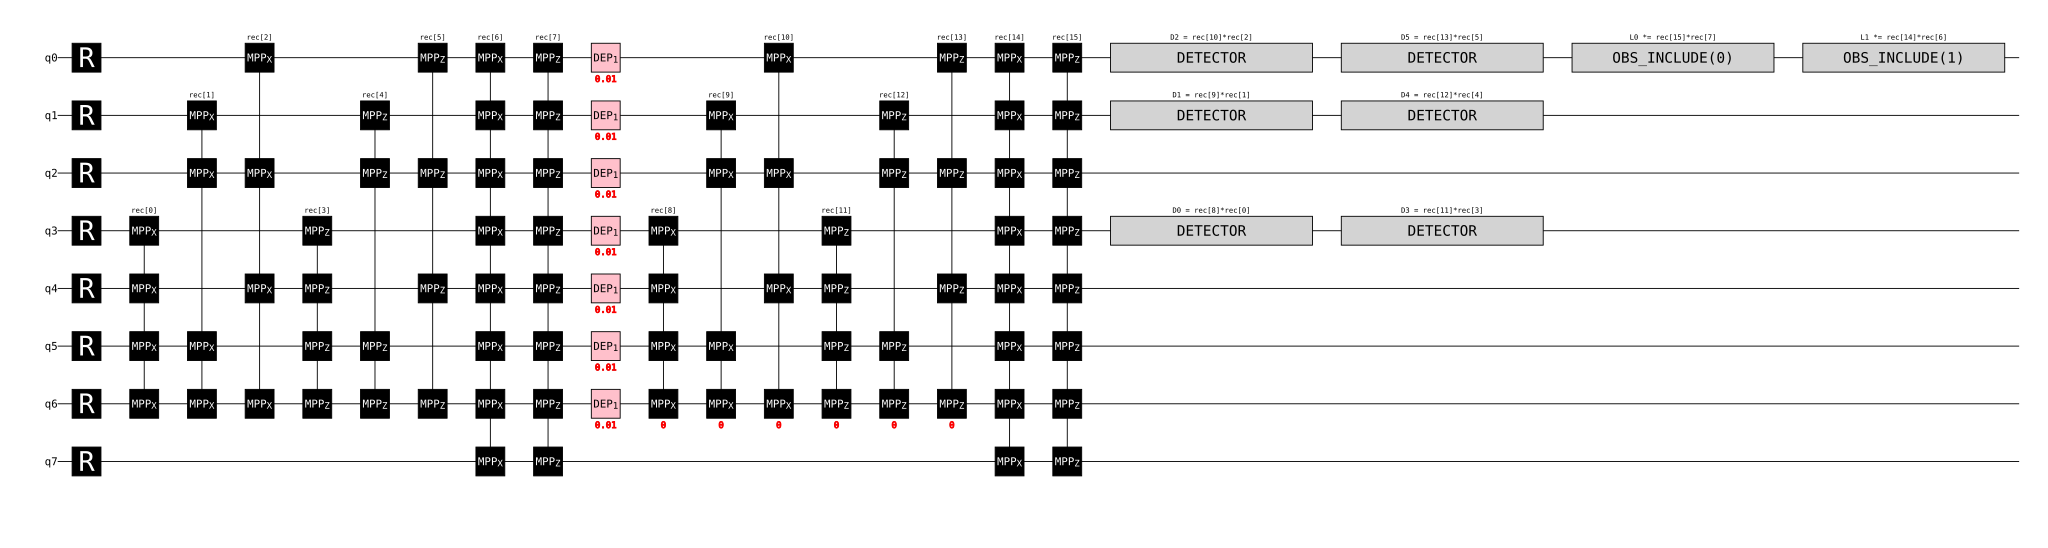

In [16]:
display(SVG(str(memory_circuit(0.01).diagram("timeline-svg"))))

> **New idea: break-even point**
>
> Seven qubits means seven chances to fail. If the noise is high, the code adds more errors than it removes.
> The noise level where the encoded qubit and a bare qubit fail equally often is the **break-even point**. Below
> it the code helps; above it, it hurts. (The related word **threshold** is used for families of codes that
> keep improving as they grow.)

<a id="q8"></a>
## Q8. Is there a point where the code stops helping?

**Short answer:** yes. With perfect checks, the Steane code stops helping at about 8 % noise per qubit.

In [17]:
lo, hi = 0.02, 0.3
for _ in range(40):                        # halve the interval until we find where the two rates meet
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if exact_failure_rate(mid) < mid else (lo, mid)
print(f"the code helps below p ≈ {(lo + hi) / 2:.3f}")

the code helps below p ≈ 0.081


A word of caution: 8 % is **not** a hardware target. It assumes perfect checks and noise only on the data.
When every gate and measurement of the checks can fail too, the bar is much lower: for the surface code it is
around 1 % per operation, and real machines aim well below that.

**What this means:** hardware quality still matters. Error correction multiplies good hardware; it can't rescue bad hardware.

> **New idea: transversal gate**
>
> To compute, we need gates on the logical qubit. A **transversal** gate is the same physical gate applied to
> each qubit of the block (gate 1 on qubit 1, gate 2 on qubit 2, ...). It's cheap, and since no gate touches two
> qubits of the same block, one faulty gate can't spread an error inside the block.
>
> To check what a gate does to the logical qubit, we follow how it changes the operators: a good logical gate
> must turn every check into a check (or a product of checks), and change $X_L$, $Z_L$ the way the intended gate would.

<a id="q9"></a>
## Q9. Can we compute on the encoded qubit?

**Short answer:** yes, and some gates come almost for free. Applying H to each of the 7 qubits acts as H on the logical qubit.

In [18]:
h_all = QuantumCircuit(7)
h_all.h(range(7))

checks = list(stabilizers().values())
print("every check stays a check:", all(any(P.evolve(h_all, frame="s").equiv(Q) for Q in checks) for P in checks))
print("X_L becomes Z_L (what an H does):", X_L.evolve(h_all, frame="s").equiv(Z_L))

psi_plus = Statevector(encoder()).evolve(h_all)
print("after H on all 7:  X_L =", round(psi_plus.expectation_value(X_L).real, 3),
      "  Z_L =", round(psi_plus.expectation_value(Z_L).real, 3), "  -> the encoded |+>")

every check stays a check: True
X_L becomes Z_L (what an H does): True
after H on all 7:  X_L = 1.0   Z_L = 0.0   -> the encoded |+>


CNOT between two blocks works the same way (qubit $k$ of one block controls qubit $k$ of the other).
The phase gate $S$ applied to all 7 qubits is almost free too, with a twist: it acts as $S^\dagger$, the
reverse of $S$, on the logical qubit.

In [19]:
s_all = QuantumCircuit(7)
s_all.s(range(7))
Y_L = 1j * X_L.dot(Z_L)                     # Y = i·X·Z on the logical qubit
after = X_L.evolve(s_all, frame="s")
print("Y_L =", Y_L, "   S on all 7 turns X_L into", after)
print("that is -Y_L, so S on all 7 is S† on the logical qubit:", after == -1 * Y_L)

Y_L = -YYYYYYY    S on all 7 turns X_L into YYYYYYY
that is -Y_L, so S on all 7 is S† on the logical qubit: True


> **New idea: T gate and magic states**
>
> H, S and CNOT alone can't run every quantum program; you also need a gate like **T**, half of an S
> ($T \cdot T = S$).
> For the Steane code, T is not transversal. It is done by preparing special helper states called
> **magic states** and consuming them. Making good magic states is one of the biggest costs in a real
> error-corrected machine.
>
> This isn't only theory: in 2022 a team in Innsbruck ran this same 7-qubit code on 16 trapped ions, did a
> logical CNOT between two encoded qubits, and applied a logical T gate using a magic state (Postler et al.,
> Nature 2022).

**What this means:** some logical gates are almost free; one essential gate is not, and that shapes how future machines are built.

> **New idea: noisy checks and repeated rounds**
>
> So far the checks were perfect. On real hardware the helper qubits, their CNOTs and their measurements fail
> too. That causes two problems:
>
> 1. **Wrong answers.** A check can report the wrong value. A wrong answer makes us "fix" a qubit that was fine.
> 2. **Spreading errors.** In Q4 one helper talks to four data qubits. If the helper goes wrong halfway, its
>    error can be copied onto several data qubits at once, more than the code can fix. Real experiments avoid
>    this with extra "flag" qubits or with helpers that are themselves encoded.
>
> Real machines handle both by repeating the checks many times and letting a decoder read all the rounds.

<a id="q10"></a>
## Q10. So why don't we have error-free quantum computers yet?

**Short answer:** three reasons. The checks are made of qubits too, so they give wrong answers. One faulty helper can spread errors onto several data qubits. And protecting one qubit well enough for long programs takes hundreds to thousands of physical qubits, plus a decoder that keeps up with the hardware. Below we measure the first one: the Steane code still helps, but only below about 5 % noise instead of 8 %.

### How we test it

We simulate the first problem (wrong answers). The second one needs a gate-by-gate model and is left for later.

The fair way to test noisy checks is a short **memory experiment**: noise hits the data, we run one round of
noisy checks, more noise hits, and at the end we read the data directly (that last reading works like one
final, trustworthy round). A **decoder** is the classical program that turns all the alarms into a fix. We
compare two:

- **trust each round:** fix whatever each round points to, right away;
- **read the rounds together:** look at all alarms at once and pick the most likely story. A check that rings
  in one round and goes quiet in the next was probably a wrong answer, not a real error.

Here the noise hits the data twice, so even perfect checks give about $32\,p^2$, twice the Q7 number. The
"no code" line gets the same two hits. With more rounds, both get more hits.

The next cell is **Behind the scenes**: run it, reading is optional.

In [20]:
# Behind the scenes: the memory experiment with noisy checks and two decoders. Safe to run without reading.
def rounds_circuit(p, check_error, rounds=1):
    "noise, a round of noisy checks (repeated `rounds` times), noise again, final perfect readout"
    checks = [pauli_product(P, [k - 1 for k in CHECKS[b]]) for P in "XZ" for b in (4, 2, 1)]
    pair = [pauli_product("X", range(8)), pauli_product("Z", range(8))]
    c, n = stim.Circuit(), 0

    def measure(groups, error=0.0):
        nonlocal n
        c.append("MPP", [t for g in groups for t in g], error)
        n += len(groups)
        return list(range(n - len(groups), n))

    c.append("R", range(8))
    prev = measure(checks); pair0 = measure(pair)
    for r in range(rounds + 1):
        c.append("DEPOLARIZE1", range(7), p)
        cur = measure(checks, 0.0 if r == rounds else check_error)   # the last one is the final readout
        for a, b in zip(cur, prev):
            c.append("DETECTOR", [stim.target_rec(a - n), stim.target_rec(b - n)])
        prev = cur
    end = measure(pair)
    c.append("OBSERVABLE_INCLUDE", [stim.target_rec(end[1] - n), stim.target_rec(pair0[1] - n)], 0)
    c.append("OBSERVABLE_INCLUDE", [stim.target_rec(end[0] - n), stim.target_rec(pair0[0] - n)], 1)
    return c


def read_together_decoder(circuit):
    "For every alarm pattern, the most likely logical flip, from all combinations of up to 2 faults."
    faults = []
    for e in circuit.detector_error_model().flattened():
        if e.type == "error":
            d = sum(1 << t.val for t in e.targets_copy() if t.is_relative_detector_id())
            o = sum(1 << t.val for t in e.targets_copy() if t.is_logical_observable_id())
            faults.append((e.args_copy()[0], d, o))
    table = {}
    for w in range(3):
        for combo in itertools.combinations(faults, w):
            pr, d, o = 1.0, 0, 0
            for q, dd, oo in combo:
                pr *= q; d ^= dd; o ^= oo
            table.setdefault(d, {}).setdefault(o, 0.0)
            table[d][o] += pr
    return {d: max(v, key=v.get) for d, v in table.items()}


def noisy_failure(p, check_error, rounds=1, shots=200_000, seed=5):
    "Failure rate of both decoders on the same runs: (trust each round, read the rounds together)."
    c = rounds_circuit(p, check_error, rounds)
    alarms, flips = c.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
    truth = flips @ np.array([1, 2])
    # trust each round: each round's bit-flip alarms flip the logical bit, phase-flip alarms flip the phase
    per_round = alarms.reshape(shots, rounds + 1, 6)
    bit = per_round[:, :, 3:6].any(axis=2).sum(axis=1) % 2
    phase = per_round[:, :, 0:3].any(axis=2).sum(axis=1) % 2
    trust = float((bit + 2 * phase != truth).mean())
    # read the rounds together
    table = read_together_decoder(c)
    keys = alarms.astype(np.int64) @ (1 << np.arange(alarms.shape[1], dtype=np.int64))
    guess = np.array([table.get(int(k), 0) for k in keys])
    return trust, float((guess != truth).mean())


def no_code(p, layers=2):
    "A bare qubit hit by the same noise twice (chance its error doesn't cancel out)."
    return 0.75 * (1 - (1 - 4 * p / 3) ** layers)

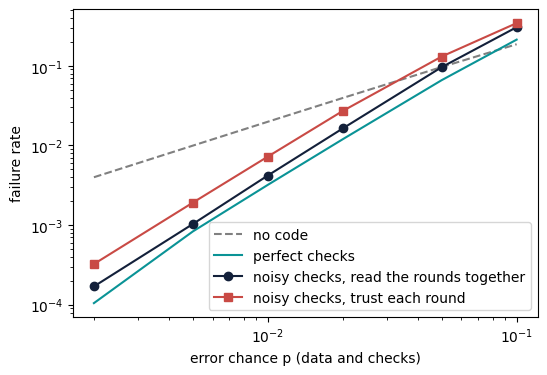

p = 0.002  failure / p²:  perfect checks    26   read together    43   trust each round    81
p = 0.005  failure / p²:  perfect checks    33   read together    41   trust each round    77
p = 0.01   failure / p²:  perfect checks    32   read together    42   trust each round    73
p = 0.02   failure / p²:  perfect checks    30   read together    41   trust each round    68
p = 0.05   failure / p²:  perfect checks    26   read together    39   trust each round    52
p = 0.1    failure / p²:  perfect checks    21   read together    31   trust each round    34



with noisy checks (read the rounds together) the code helps below p ≈ 0.05  (Q8, perfect checks: about 0.08)


In [21]:
ROUNDS = 1                                   # rounds of noisy checks; try 3
ps10 = np.array([0.002, 0.005, 0.01, 0.02, 0.05, 0.1])
perfect = np.array([noisy_failure(p, 0.0, ROUNDS)[1] for p in ps10])
trust, together = np.array([noisy_failure(p, p, ROUNDS) for p in ps10]).T
bare = no_code(ps10, layers=ROUNDS + 1)      # the bare qubit waits through the same noise

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ps10, bare, "--", color="gray", label="no code")
ax.loglog(ps10, perfect, "-", color="#0A9396", label="perfect checks")
ax.loglog(ps10, together, "o-", color="#13203A", label="noisy checks, read the rounds together")
ax.loglog(ps10, trust, "s-", color="#C94A45", label="noisy checks, trust each round")
ax.set_xlabel("error chance p (data and checks)"); ax.set_ylabel("failure rate"); ax.legend(); plt.show()

for p, a, b, c in zip(ps10, perfect, together, trust):
    print(f"p = {p:<6} failure / p²:  perfect checks {a / p**2:5.0f}   read together {b / p**2:5.0f}   "
          f"trust each round {c / p**2:5.0f}")

lo, hi = 0.01, 0.1
for _ in range(12):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if noisy_failure(mid, mid, ROUNDS)[1] < no_code(mid, ROUNDS + 1) else (lo, mid)
print(f"\nwith noisy checks (read the rounds together) the code helps below p ≈ {(lo + hi) / 2:.2f}"
      "  (Q8, perfect checks: about 0.08)")

**What this means:** noisy checks don't break the code, but they make it weaker: failures still fall like $p^2$, just with a bigger number in front, and the code helps over a smaller range. How you read the alarms matters as much as the hardware. Real machines go further: they repeat the checks many times, run the decoder in real time, protect the checks against spreading errors, and use codes that grow, such as the **surface code** (qubits on a grid, each check on neighbors) or **qLDPC codes** (fewer qubits, longer-range links). That engineering, not the idea, is what the field is racing to finish.

<a id="takeaways"></a>
## Key takeaways

1. You can't copy a qubit, but you can ask questions about groups of qubits.
2. Three checks worth 4, 2 and 1 point straight at the broken qubit.
3. Checking bit flips and phase flips separately covers any single error.
4. With perfect checks, the logical qubit fails about $16\,p^2$ of the time and helps below about 8 % noise.
   With noisy checks it still helps, but only below about 5 %, and a good decoder matters.
5. Some gates come almost free; the T gate does not.
6. The hard part is doing all of this with noisy checks, fast, at scale.

## Try it yourself

- Change `p` in Q7 and see how fast the failures drop.
- Add your own errors with `fixed(("x", 1), ("z", 4))` or `data_after(..., start="+")`.
- In Q10, set `ROUNDS = 3`, or give the checks a different error chance than the data, and watch the two
  decoders.

## What's next

The Steane code protects one qubit against one error. The machines being built now use codes that grow: the
**surface code** puts qubits on a grid and gets better every time the grid grows, as long as the hardware is
below its threshold. In 2024 Google's Willow chip showed exactly that: each step up in grid size cut the
logical error rate roughly in half, and a decoder kept up in real time at distance 5 (Google Quantum AI,
Nature 2025).
Repeated rounds of checks, real-time decoders and magic-state factories turn that into a computer. Those are
the topics for the next notebooks.

Why does it matter? Error correction is what turns today's machines into ones that can run the big
algorithms. For example, breaking a 2048-bit RSA key with Shor's algorithm needs millions of physical qubits
(about 20 million in a well-known 2019 estimate) to run about 6,000 logical ones: almost all of them are
spent on error correction. The full count is worked out in
[shor-resource-estimate](https://github.com/MaldoAlberto/shor-resource-estimate).

If you run this with other noise levels or another code, share your plot and tag **@qalycat**. Questions and
corrections are welcome.

## Glossary

| Term | In one line |
|---|---|
| Qubit | The basic unit of quantum information: 0, 1, or a superposition of both. |
| Superposition | A qubit state that is part 0 and part 1, like $\vert+\rangle$. |
| Bit flip ($X$) | Error that swaps 0 and 1. |
| Phase flip ($Z$) | Error that swaps $\vert+\rangle$ and $\vert-\rangle$; invisible when reading 0/1. |
| Parity check | Asks whether a group has an even or odd number of 1s, without revealing the bits. |
| Syndrome | The list of check answers; here it names the broken qubit. |
| Logical qubit | One qubit of information spread over several physical qubits. |
| Stabilizer | A check written as an operator; healthy states answer $+1$. |
| Ancilla | A helper qubit used to read a check without measuring the data. |
| Pauli operators | The basic errors and gates $X$, $Y$, $Z$ on one qubit. |
| Entangled | Qubits linked so that measuring one tells you about the other. |
| Memory experiment | Keep a logical qubit alive for some rounds, then check that it is still right. |
| Dynamic circuit | A circuit that measures in the middle and acts on the result. |
| Code distance | The fewest errors that change the logical qubit with no check noticing (3 for Steane). |
| CSS code | A code whose bit-flip and phase-flip checks work independently. |
| Depolarizing noise | Each qubit gets a random $X$, $Y$ or $Z$ error with chance $p$. |
| Break-even | The noise level where the encoded qubit and a bare qubit fail equally often (also called pseudo-threshold). |
| Threshold | The noise level below which a growing family of codes keeps getting better. |
| Transversal gate | The same gate on each qubit of the block; can't spread errors inside the block. |
| Magic state | A special prepared state used to perform the T gate. |
| Decoder | The classical program that turns check answers (from all rounds) into fixes. |

<a id="additional-information"></a>
# Additional information

**Created by:** Alberto Maldonado Romo (@qalycat)

**License:** MIT. You can use, change and share this notebook; keep the copyright notice (see `LICENSE`).

**References:**
- A. M. Steane, "Error correcting codes in quantum theory", Phys. Rev. Lett. 77, 793 (1996).
- R. W. Hamming, "Error detecting and error correcting codes", Bell Syst. Tech. J. 29, 147 (1950).
- W. K. Wootters, W. H. Zurek, "A single quantum cannot be cloned", Nature 299, 802 (1982).
- L. Postler et al., "Demonstration of fault-tolerant universal quantum gate operations", Nature 605, 675 (2022).
- Google Quantum AI and collaborators, "Quantum error correction below the surface code threshold", Nature 638, 920 (2025).
- C. Gidney, "Stim: a fast stabilizer circuit simulator", Quantum 5, 497 (2021).